# Avaliação da VeritAI

Notebook da entrega de documentação e validação dos modelos de IA (Grupo 5, Challenge 1, Residência em IA — Instituto Eldorado / UnB Gama). Ele **carrega, executa e avalia** a VeritAI, o serviço de verificação de afirmações do FOMO, e reúne as métricas citadas no relatório técnico.

**A VeritAI não tem modelo treinado pela equipe.** Ela combina modelos pré-treinados públicos (embedding de sentenças e inferência em linguagem natural, NLI) com regras explícitas e versionadas. "Carregar o modelo" aqui significa carregar esses modelos e a configuração (`veritai/config.json`); não há pesos próprios a carregar.

**Como rodar:** kernel `VeritAI (.venv)` (o `.venv` do repositório `veritai`, com `pip install -e ".[modelos,dev,notebook]"`), a partir de `veritai-dados/avaliacao/`. A base própria precisa estar em `veritai/data/veritai.sqlite3` (restaurada de `artefatos/veritai.sqlite3.gz` e migrada com `python -m veritai.base migrar`). A execução completa, com as partes ao vivo, leva poucos minutos num Mac M4; as tabelas completas vêm da última execução da bateria (`avaliacao/bateria.py`), porque rodá-la leva de 30 a 45 minutos. Para rodar tudo de novo aqui, mude `RODAR_BATERIA` para `True`.

**Sobre os rótulos:** os conjuntos de releases (desenvolvimento e validação), as checagens e uma amostra dos vizinhos foram escritos por IA e **conferidos por um anotador**, com concordância total; os demais conjuntos são pré-rotulagem. Os números orientam decisões; não são medida definitiva (falta segundo anotador).

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path

AQUI = Path.cwd()
DADOS = AQUI.parent if AQUI.name == "avaliacao" else AQUI
VERITAI = DADOS.parent / "veritai"
sys.path[:0] = [str(VERITAI), str(VERITAI / "eval"), str(DADOS / "avaliacao")]
os.environ.setdefault("VERITAI_BASE", str(VERITAI / "data" / "veritai.sqlite3"))

import pandas as pd
import matplotlib.pyplot as plt

import avaliar
import bateria
from veritai.config import CONFIG, LIMIARES, VERIFICADOR, caminho_base, perfil

RODAR_BATERIA = False  # True roda a bateria completa aqui (30 a 45 min)
FIGURAS = DADOS / "avaliacao" / "figuras"
FIGURAS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=DADOS, capture_output=True, text=True).stdout.strip()
print(f"commit {commit} | config {CONFIG['versao_config']} | limiares {dict((k, v) for k, v in LIMIARES.items() if not k.startswith('_'))}")
print(f"base própria: {caminho_base()} ({'existe' if caminho_base().exists() else 'NÃO ENCONTRADA'})")

commit b41d8cb | config 2026-10-08.2 | limiares {'similaridade_selecao': 0.38, 'similaridade_forte': 0.43, 'nli_forte': 0.72}
base própria: /Users/aluno2/Desktop/fomo-veritai-local/veritai/data/veritai.sqlite3 (existe)


## 1. Carregar os modelos

**Pergunta:** quais modelos a VeritAI usa, e quanto custa carregá-los?

**Por que importa:** a abordagem escolhida usa modelos prontos; a escolha entre os perfis V0 e V1 é a principal decisão de modelo do projeto.

In [2]:
from veritai.modelos import ComparadorNLI

perfis = pd.DataFrame([{"perfil": nome, **{k: v for k, v in perfil(nome).items() if k in ("embedding", "nli")}} for nome in ("v0", "v1")])
display(perfis)
comparadores, tempos = {}, {}
for nome in ("v0", "v1"):
    inicio = time.perf_counter()
    comparadores[nome] = ComparadorNLI(nome)
    comparadores[nome].modelos._carregar()
    tempos[nome] = time.perf_counter() - inicio
print({k: f"{v:.1f} s" for k, v in tempos.items()})

,perfil,embedding,nli
0,v0,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli
1,v1,intfloat/multilingual-e5-base,MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7


/Users/aluno2/Desktop/fomo-veritai-local/veritai/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 21837.33it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

...

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 18764.56it/s]

/Users/aluno2/Desktop/fomo-veritai-local/veritai/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 7655.02it/s]

{'v0': '7.8 s', 'v1': '5.9 s'}


**Conclusão:** os dois perfis carregam em segundos depois do primeiro download (cerca de 0,5 GB para a V0 e 1,7 GB para a V1). O NLI da V1 é carregado em float32: em float16, o padrão do checkpoint, ele ficava cerca de 7 vezes mais lento em CPU.

## 2. Executar: uma notícia de ponta a ponta

**Pergunta:** como a VeritAI processa uma notícia, da extração das afirmações ao resultado?

O exemplo usa a API real (`criar_app`), com a base própria e sem busca na web: primeiro o `POST /extrair` propõe afirmações a partir de uma notícia; depois o `POST /analisar` verifica duas afirmações, uma correta e uma com o número trocado.

In [3]:
import sqlite3
from fastapi.testclient import TestClient
from veritai.api import criar_app
from veritai.base import BaseEvidencias
from veritai.fontes import buscar_fontes

comparador = comparadores["v1"]
base = BaseEvidencias(caminho_base(), perfil("v1")["embedding"], comparador.modelos.vetorizar, "v1")
cliente = TestClient(criar_app(comparador, buscar_fontes, base))

titulo, texto, data = sqlite3.connect(caminho_base()).execute(
    "SELECT titulo, texto, data_publicacao FROM documentos WHERE titulo LIKE 'IPCA fica em 0,48% em setembro%' LIMIT 1").fetchone()
extraidas = cliente.post("/extrair", json={"noticia": {"titulo": titulo, "texto": texto[:3000], "data": data}, "maximo": 3}).json()
pd.DataFrame(extraidas["afirmacoes"])[["texto", "sinais", "alertas"]]

/Users/aluno2/Desktop/fomo-veritai-local/veritai/.venv/lib/python3.14/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


,texto,sinais,alertas
0,"O Índice Nacional de Preços ao Consumidor Amplo (IPCA) do mês de setembro de 2025 foi 0,48%, 0,59 ponto percentual (...","[número, período, nome próprio, verbo de fato]",[]
1,"IPCA fica em 0,48% em setembro de 2025","[número, período, nome próprio]",[]
2,"No ano, o IPCA acumula alta de 3,64% e, nos últimos 12 meses, o índice ficou em 5,17%, acima dos 5,13%","[número, nome próprio, verbo de fato]",[sem período: o verificador não confere a data]


In [4]:
pedido = {"noticia": {"titulo": "Teste", "data": data}, "buscar_na_web": False,
          "afirmacoes": ["O IPCA de setembro de 2025 foi de 0,48%.", "O IPCA de setembro de 2025 foi de 0,84%."]}
relatorio = cliente.post("/analisar", json=pedido).json()
for item in relatorio["afirmacoes"]:
    print(f"{item['afirmacao']}\n  → {item['resultado']} | fontes independentes: {item['fontes_independentes']} | {item['justificativa']}")
    for e in item["evidencias"][:2]:
        print(f"     [{e['relacao']}] sim {e['similaridade']:.2f} NLI {e['pontuacao_nli']:.2f} | {e['trecho'][:110]}")
print("versões:", relatorio["versoes"])

O IPCA de setembro de 2025 foi de 0,48%.
  → SUPPORTED | fontes independentes: 1 | 1 fonte(s) independente(s) trazem trechos que apoiam a afirmação, e nenhuma fonte com relação forte a contradiz.
     [apoia] sim 0.85 NLI 1.00 | O Índice Nacional de Preços ao Consumidor Amplo (IPCA) do mês de setembro foi 0,48%, 0,59 ponto percentual (p.
     [neutro] sim 0.84 NLI 1.00 | No ano, o IPCA acumula alta de 3,64% e, nos últimos 12 meses, o índice ficou em 5,17%, acima dos 5,13%
O IPCA de setembro de 2025 foi de 0,84%.
  → REFUTED | fontes independentes: 1 | 1 fonte(s) independente(s) trazem trechos que contradizem a afirmação, e nenhuma fonte com relação forte a apoia.
     [contradiz] sim 0.87 NLI 0.98 | O Índice Nacional de Preços ao Consumidor Amplo (IPCA) do mês de setembro foi 0,48%, 0,59 ponto percentual (p.
     [neutro] sim 0.87 NLI 1.00 | O Índice Nacional de Preços ao Consumidor Amplo (IPCA) de setembro foi de 0,44% e ficou 0,46 ponto percentual 
versões: {'modelo': 'veritai-v1', '

**Conclusão:** cada afirmação recebe um resultado próprio, com as evidências, a relação atribuída a cada trecho e a justificativa gerada pelas regras. A porcentagem fica sempre `null`: o sistema não está calibrado.

## 3. Avaliar: métricas

**Métricas usadas** (todas por afirmação):

- **macro-F1**, com intervalo de confiança de 95% por bootstrap; quando se comparam sistemas que preveem conjuntos de classes diferentes, usa-se também o macro-F1 sobre as classes dos rótulos;
- **falsas aprovações**: SUPPORTED quando o rótulo é outro (o erro mais grave para a plataforma);
- **falsas refutações**: REFUTED quando o rótulo é SUPPORTED (alarme falso para o revisor);
- **taxa de NEE** predita;
- **itens frágeis**: a decisão muda se um limiar de "forte" se mover 0,02;
- **recall da busca** (vizinhos): o documento certo está entre as evidências.

**Conjuntos:** releases — desenvolvimento (65) e validação (43); contraste (28, só sanidade); vizinhos com busca na base (140); AVeriTeC dev em português (AVERITEC-BR, 424) e inglês (500), como teste de estresse; teste intocado (treino do AVeriTeC).

### 3.1 Avaliação ao vivo (V1, verificador padrão)

In [5]:
ao_vivo = []
for nome in ("dev", "val", "con"):
    inicio = time.perf_counter()
    predicoes = bateria.rodar_conjunto_com_evidencias(comparadores["v1"], avaliar.carregar(bateria.CONJUNTOS[nome]))
    m = bateria.metricas(predicoes)
    ao_vivo.append({"conjunto": nome, "n": m["n"], "macro-F1": round(m["macro_f1"], 3), "IC95": tuple(round(x, 3) for x in m["macro_f1_ic95"]),
                    "falsas aprovações": f"{m['falsas_aprovacoes']:.1%}", "falsas refutações": f"{m['falsas_refutacoes']:.1%}" if m["falsas_refutacoes"] is not None else "—",
                    "NEE": f"{m['taxa_nee']:.1%}", "segundos": round(time.perf_counter() - inicio, 1)})
pd.DataFrame(ao_vivo)

,conjunto,n,macro-F1,IC95,falsas aprovações,falsas refutações,NEE,segundos
0,dev,65,0.564,"(0.472, 0.843)",6.1%,3.1%,20.0%,22.8
1,val,43,0.589,"(0.487, 0.894)",4.8%,4.5%,23.3%,9.8
2,con,28,0.608,"(0.418, 0.782)",0.0%,0.0%,53.6%,1.5


### 3.2 Bateria completa (perfis × verificador × conjuntos)

In [6]:
if RODAR_BATERIA:
    subprocess.run([sys.executable, str(DADOS / "avaliacao" / "bateria.py"), "--nome", "completa"], cwd=DADOS, check=True)
pastas = sorted((DADOS / "saida" / "bateria").glob("*-completa"))
assert pastas, "Rode avaliacao/bateria.py --nome completa (ou RODAR_BATERIA = True)."
PASTA_BATERIA = pastas[-1]
resumo = json.loads((PASTA_BATERIA / "resumo.json").read_text(encoding="utf-8"))
tabela = pd.DataFrame(resumo["resultados"])
print(f"bateria: {PASTA_BATERIA.name} (commit {resumo['commit']})")
mostrar = tabela.assign(**{
    "macro-F1": tabela.macro_f1.round(3),
    "falsas aprov.": (100 * tabela.falsas_aprovacoes).round(1),
    "falsas refut.": (100 * tabela.falsas_refutacoes).round(1),
    "NEE %": (100 * tabela.taxa_nee).round(1),
    "recall busca %": (100 * tabela.get("recall_busca")).round(1),
})[["conjunto", "perfil", "config", "n", "macro-F1", "falsas aprov.", "falsas refut.", "NEE %", "frageis", "recall busca %"]]
mostrar

bateria: 20261008T1556-6878e33-modificado-completa (commit 6878e33-modificado)


,conjunto,perfil,config,n,macro-F1,falsas aprov.,falsas refut.,NEE %,frageis,recall busca %
0,dev,v1,padrao,65,0.564,6.1,3.1,20.0,1,NaN
1,val,v1,padrao,43,0.589,4.8,4.5,23.3,0,NaN
2,con,v1,padrao,28,0.608,0.0,0.0,53.6,0,NaN
3,avbr,v1,padrao,424,0.193,3.7,4.9,78.5,4,NaN
4,aven,v1,padrao,500,0.172,6.1,4.9,77.4,3,NaN
5,viz,v1,padrao,140,0.617,0.0,0.0,24.3,2,98.1
6,dev,v1,sem,65,0.436,3.0,6.2,30.8,2,NaN
7,val,v1,sem,43,0.423,9.5,4.5,41.9,1,NaN
8,con,v1,sem,28,0.639,0.0,0.0,50.0,0,NaN
9,avbr,v1,sem,424,0.313,7.8,4.9,55.0,14,NaN


### 3.3 Ablação do verificador

**Pergunta:** o verificador (regras de entidade, período e número depois do NLI) ajuda ou atrapalha, e onde?

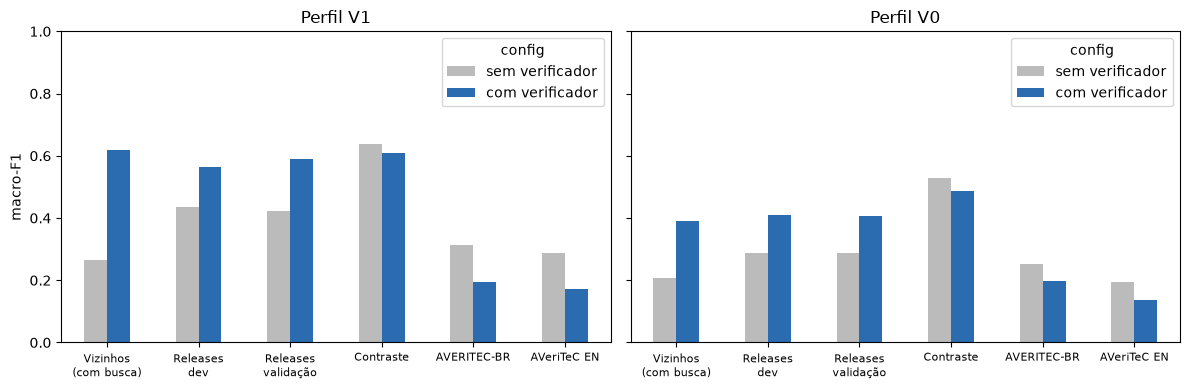

In [7]:
ordem = ["viz", "dev", "val", "con", "avbr", "aven"]
nomes = {"viz": "Vizinhos\n(com busca)", "dev": "Releases\ndev", "val": "Releases\nvalidação", "con": "Contraste", "avbr": "AVERITEC-BR", "aven": "AVeriTeC EN"}
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eixo, nome_perfil in zip(eixos, ("v1", "v0")):
    t = tabela[tabela.perfil == nome_perfil].pivot(index="conjunto", columns="config", values="macro_f1").reindex([c for c in ordem if c in set(tabela.conjunto)])
    t[["sem", "padrao"]].rename(columns={"sem": "sem verificador", "padrao": "com verificador"}).plot.bar(ax=eixo, rot=0, color=["#bbbbbb", "#2b6cb0"])
    eixo.set_xticklabels([nomes[c] for c in t.index], fontsize=8)
    eixo.set_title(f"Perfil {nome_perfil.upper()}"); eixo.set_xlabel(""); eixo.set_ylabel("macro-F1"); eixo.set_ylim(0, 1)
fig.tight_layout(); fig.savefig(FIGURAS / "ablacao_verificador.png", dpi=200); plt.show()

**Conclusão:** com busca na base (vizinhos), o verificador é indispensável: sem ele, releases de outros meses e de outros indicadores apoiam ou contradizem a afirmação errada. Com evidência-ouro (AVeriTeC), em que toda evidência é sobre a alegação, ele custa acertos, porque bloqueia refutações por troca de entidade ou data. O cenário de produção é o com busca.

### 3.4 Matrizes de confusão (V1, verificador padrão)

In [8]:
def matriz(conjunto, nome_perfil="v1", config="padrao"):
    predicoes = [json.loads(l) for l in (PASTA_BATERIA / "predicoes" / f"{conjunto}-{nome_perfil}-{config}.jsonl").read_text(encoding="utf-8").splitlines()]
    curto = {"SUPPORTED": "S", "REFUTED": "R", "NOT_ENOUGH_EVIDENCE": "NEE", "CONFLICTING_EVIDENCE": "CE"}
    return pd.crosstab(pd.Series([curto[p["rotulo"]] for p in predicoes], name="rótulo"), pd.Series([curto[p["predito"]] for p in predicoes], name="predição"))
for conjunto in ("val", "viz", "avbr"):
    print(conjunto); display(matriz(conjunto))

val


predição,CE,NEE,R,S
rótulo,,,,
NEE,0,5,0,0
R,0,4,11,1
S,1,1,1,19


viz


predição,CE,NEE,R,S
rótulo,,,,
NEE,0,27,8,0
R,1,6,63,0
S,11,1,0,23


avbr


predição,CE,NEE,R,S
rótulo,,,,
CE,1,23,2,2
NEE,0,28,2,0
R,5,202,46,10
S,0,80,5,18


## 4. Limiares de decisão

**Pergunta:** os limiares de "forte" (similaridade ≥ 0,43 e NLI ≥ 0,72) são adequados?

**Por que importa:** eles foram definidos como exemplos na fase de requisitos, antes da escolha dos modelos, e nunca tinham sido medidos. A varredura usa os trechos salvos pela bateria (sem rodar os modelos) e escolhe só no desenvolvimento.

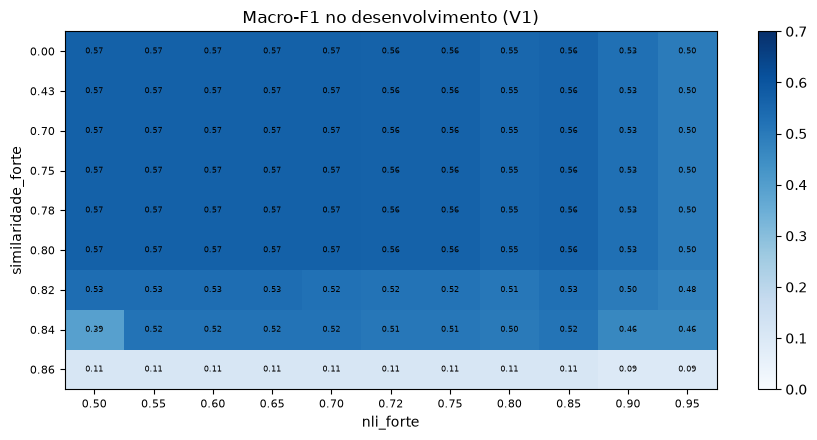

In [9]:
import limiares
dev_v1 = limiares.ler(PASTA_BATERIA, "dev", "v1", "padrao")
grade = pd.DataFrame([[limiares.medir(dev_v1, s, n)[0] for n in sorted(set(limiares.NLIS))] for s in limiares.SIMILARIDADES],
                     index=limiares.SIMILARIDADES, columns=sorted(set(limiares.NLIS)))
fig, eixo = plt.subplots(figsize=(9, 4.5))
imagem = eixo.imshow(grade.values, cmap="Blues", vmin=0, vmax=0.7, aspect="auto")
eixo.set_xticks(range(len(grade.columns)), [f"{c:.2f}" for c in grade.columns], fontsize=8)
eixo.set_yticks(range(len(grade.index)), [f"{i:.2f}" for i in grade.index], fontsize=8)
eixo.set_xlabel("nli_forte"); eixo.set_ylabel("similaridade_forte"); eixo.set_title("Macro-F1 no desenvolvimento (V1)")
for i in range(grade.shape[0]):
    for j in range(grade.shape[1]):
        eixo.text(j, i, f"{grade.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(imagem); fig.tight_layout(); fig.savefig(FIGURAS / "limiares_v1.png", dpi=200); plt.show()

**Conclusão:** na V1, a similaridade não atua até 0,80 (o embedding e5 dá mais de 0,80 a todas as evidências) e o NLI fica num platô entre 0,50 e 0,75, com diferença de um item em 65. Os dados não justificam mudar os limiares; a validação e os vizinhos confirmam que baixar o limiar do NLI cria falsas refutações.

## 5. Teste intocado

**Pergunta:** como a configuração final se sai em dados nunca usados para ajustar regras ou limiares?

O treino do AVeriTeC (3.068 alegações em inglês; 2.683 em português pelo AVERITEC-BR, sem as traduções truncadas) foi rodado **uma única vez**, com a configuração final (verificador padrão). É evidência-ouro em perguntas e respostas, de 2020 e centrada nos EUA: mede raciocínio sobre evidência, não o domínio brasileiro.

In [10]:
intocados = sorted((DADOS / "saida" / "bateria").glob("*-intocado"))
if intocados:
    r = json.loads((intocados[-1] / "resumo.json").read_text(encoding="utf-8"))
    t = pd.DataFrame(r["resultados"])
    display(t.assign(**{"IC95": t.macro_f1_ic95.map(lambda x: tuple(round(v, 3) for v in x))})[["conjunto", "perfil", "n", "macro_f1", "IC95", "falsas_aprovacoes", "falsas_refutacoes", "taxa_nee"]].round(3))
else:
    print("Teste intocado ainda não rodado: avaliacao/bateria.py --perfis v1 v0 --configs padrao --conjuntos avbr_teste aven_teste --nome intocado")

,conjunto,perfil,n,macro_f1,IC95,falsas_aprovacoes,falsas_refutacoes,taxa_nee
0,avbr_teste,v1,2683,0.201,"(0.186, 0.219)",0.053,0.056,0.761
1,aven_teste,v1,3068,0.205,"(0.19, 0.22)",0.056,0.057,0.758
2,avbr_teste,v0,2683,0.163,"(0.149, 0.177)",0.124,0.063,0.769
3,aven_teste,v0,3068,0.140,"(0.127, 0.154)",0.097,0.037,0.825


## 6. Extração automática de afirmações

**Pergunta:** a extração por regras (`POST /extrair`) propõe afirmações aproveitáveis?

A amostra de 150 candidatas, de 30 notícias reais da base, foi pré-rotulada por IA (subagente Claude Sonnet, sem ver os sinais do extrator): verificável, um fato só, compreensível sozinha.

In [11]:
pre = pd.read_csv(DADOS / "rotulos" / "extracao-v0" / "pre-rotulos-ia.csv")
verificaveis = pre[pre["verificavel (s/n)"] == "s"]
prontas = verificaveis[(verificaveis["atomica (s/n)"] == "s") & (verificaveis["compreensivel_sozinha (s/n)"] == "s")]
pd.DataFrame([{"candidatas": len(pre), "verificáveis": f"{len(verificaveis)} ({len(verificaveis)/len(pre):.0%})",
               "um fato só (entre verificáveis)": f"{(verificaveis['atomica (s/n)'] == 's').mean():.0%}",
               "compreensíveis sozinhas": f"{(verificaveis['compreensivel_sozinha (s/n)'] == 's').mean():.0%}",
               "prontas sem edição": f"{len(prontas)} ({len(prontas)/len(verificaveis):.0%})"}])

,candidatas,verificáveis,um fato só (entre verificáveis),compreensíveis sozinhas,prontas sem edição
0,150,135 (90%),53%,22%,16 (12%)


**Conclusão:** as regras escolhem bem quais frases propor (90% verificáveis), mas quase todas precisam de edição pelo publicador (falta sujeito ou ano, ou há vários fatos na frase). Por isso o `/extrair` só propõe: o publicador confirma antes do `/analisar`.

## 7. Notícias reais de ponta a ponta

**Pergunta:** no cenário mais próximo do uso real (afirmações extraídas de notícias, busca na base sem a notícia de origem), a VeritAI concorda com a conferência humana? E uma IA conferindo, concorda?

In [12]:
conferencia = pd.read_csv(DADOS / "rotulos" / "noticias-reais-v0" / "conferencia.csv")
coluna = "rotulo (apoiada/refutada/insuficiente/conflitante)"
preenchidos = conferencia[coluna].notna().sum()
if preenchidos:
    subprocess.run([sys.executable, str(DADOS / "investigacoes" / "comparar_conferencias.py")], cwd=DADOS, check=True)
else:
    print(f"Conferência humana ainda não feita ({len(conferencia)} afirmações). Os resultados da VeritAI e da IA não são mostrados para manter a conferência cega.")

Conferência humana ainda não feita (71 afirmações). Os resultados da VeritAI e da IA não são mostrados para manter a conferência cega.


## 8. Tempo de execução

**Pergunta:** quanto custa analisar uma afirmação em cada perfil (Mac M4, só CPU)?

In [13]:
itens = avaliar.carregar(bateria.CONJUNTOS["val"])[:15]
custo = {}
for nome in ("v0", "v1"):
    inicio = time.perf_counter()
    for item in itens:
        comparadores[nome].comparar(item["afirmacao"], avaliar.fontes_do_item(item))
    custo[nome] = (time.perf_counter() - inicio) / len(itens)
pd.DataFrame([{"perfil": k, "segundos por afirmação (evidências fornecidas)": round(v, 2)} for k, v in custo.items()])

,perfil,segundos por afirmação (evidências fornecidas)
0,v0,0.02
1,v1,0.09


## Resumo

Os números deste notebook alimentam o relatório técnico. Pontos principais: a VeritAI usa modelos pré-treinados e regras, sem treinamento próprio; a V1 é melhor que a V0 em quase todos os conjuntos (empatam no AVERITEC-BR com verificador); o verificador é decisivo no cenário com busca; os limiares estão num platô; a extração por regras escolhe bem as frases, mas não as descontextualiza; e as métricas por classe rara (insuficiente, conflitante) não são estáveis com os tamanhos atuais.